# BÀI THỰC HÀNH CHƯƠNG 2 (PHẦN 2)
## PHƯƠNG PHÁP PHÁT HIỆN BIÊN CANNY (CANNY EDGE DETECTOR)

Notebook sử dụng ảnh mẫu có sẵn trong thư viện Scikit-image để có thể chạy mà không cần tải ảnh ngoài.

# I. LÝ THUYẾT: CANNY EDGE DETECTOR

## 1. Tìm hiểu về các bước của thuật toán Canny

Canny Edge Detector là thuật toán phát hiện biên trong xử lý ảnh. Biên là những vị trí có sự thay đổi rõ rệt về cường độ sáng giữa các vùng trong ảnh. Việc phát hiện biên giúp xác định đường viền, hình dạng và ranh giới của các đối tượng.

Thuật toán Canny gồm năm bước chính: giảm nhiễu, tính toán gradient, loại bỏ điểm không cực đại, áp dụng ngưỡng kép và theo dõi cạnh.

### a. Giải thích chi tiết từng bước

**Bước 1: Giảm nhiễu (Noise Reduction)**

Trước khi phát hiện biên, thuật toán sử dụng bộ lọc Gaussian để làm mượt ảnh và giảm nhiễu. Nhiễu có thể xuất hiện trong quá trình chụp ảnh hoặc do điều kiện ánh sáng không tốt. Nếu không giảm nhiễu, thuật toán có thể phát hiện nhầm các điểm nhiễu thành đường biên.

Ví dụ: Khi xử lý ảnh đồng xu có nhiều chấm nhiễu nhỏ, bộ lọc Gaussian giúp giảm các chi tiết không cần thiết và làm cho đường viền đồng xu dễ phát hiện hơn.

**Bước 2: Tính toán gradient (Gradient Calculation)**

Sau khi giảm nhiễu, thuật toán tính gradient để xác định mức độ và hướng thay đổi cường độ sáng tại mỗi điểm ảnh.

Gradient có giá trị lớn thường xuất hiện tại những vị trí có sự thay đổi độ sáng mạnh, chẳng hạn ranh giới giữa một vật thể và nền ảnh. Những vị trí này có khả năng là đường biên.

**Bước 3: Loại bỏ điểm không cực đại (Non-Maximum Suppression)**

Sau bước tính gradient, các vùng biên có thể vẫn dày hoặc rộng nhiều pixel. Non-Maximum Suppression giúp làm mảnh đường biên bằng cách giữ lại các điểm có giá trị gradient lớn nhất theo hướng gradient và loại bỏ những điểm lân cận yếu hơn.

Nhờ đó, đường biên thu được thường mảnh và rõ hơn, giúp xác định ranh giới của đối tượng chính xác hơn.

**Bước 4: Áp dụng ngưỡng kép (Double Threshold)**

Thuật toán sử dụng hai ngưỡng: ngưỡng thấp và ngưỡng cao để phân loại các điểm có khả năng là biên.

- **Biên mạnh:** Có gradient lớn hơn ngưỡng cao. Những điểm này được xem là biên đáng tin cậy.
- **Biên yếu:** Có gradient nằm giữa ngưỡng thấp và ngưỡng cao. Những điểm này cần được kiểm tra thêm.
- **Không phải biên:** Có gradient thấp hơn ngưỡng thấp và bị loại bỏ.

Sử dụng hai ngưỡng giúp thuật toán giữ lại những biên rõ ràng, đồng thời xem xét các biên yếu thay vì loại bỏ tất cả ngay lập tức.

**Bước 5: Theo dõi cạnh (Edge Tracking by Hysteresis)**

Ở bước cuối cùng, thuật toán kiểm tra mối liên kết giữa các điểm biên. Những điểm biên yếu có kết nối với biên mạnh sẽ được giữ lại, trong khi các điểm biên yếu không liên kết với biên mạnh sẽ bị loại bỏ.

Bước này giúp giữ lại các đường biên thật nhưng có một số đoạn yếu, đồng thời hạn chế những đường biên giả do nhiễu tạo ra.

**Kết luận:** Năm bước xử lý giúp Canny tạo ra các đường biên tương đối mảnh, rõ ràng và ít bị ảnh hưởng bởi nhiễu hơn so với phương pháp chỉ tính gradient đơn giản.

### b. So sánh Canny với các thuật toán khác như Sobel và Laplacian

Sobel, Laplacian và Canny đều được sử dụng để phát hiện biên trong ảnh, nhưng có nguyên lý hoạt động và đặc điểm khác nhau.

| Tiêu chí | Sobel | Laplacian | Canny |
|---|---|---|---|
| Nguyên lý | Tính gradient theo hướng ngang và dọc | Sử dụng đạo hàm bậc hai | Kết hợp làm mượt, gradient, làm mảnh biên và ngưỡng kép |
| Độ mảnh của biên | Biên có thể dày | Có thể tạo ra biên kép | Thường tạo ra biên mảnh hơn |
| Khả năng xử lý nhiễu | Có thể bị ảnh hưởng bởi nhiễu | Khá nhạy với nhiễu | Có bước Gaussian để giảm nhiễu |
| Tốc độ xử lý | Thường nhanh | Thường nhanh | Thường chậm hơn do có nhiều bước |
| Độ phức tạp | Thấp | Thấp đến trung bình | Cao hơn |
| Ưu điểm | Đơn giản, dễ thực hiện | Phát hiện sự thay đổi cường độ sáng theo nhiều hướng | Biên thường rõ, mảnh và hạn chế một phần biên giả |
| Nhược điểm | Có thể tạo biên dày | Dễ bị ảnh hưởng bởi nhiễu | Cần điều chỉnh các tham số phù hợp |

Nhìn chung, Sobel phù hợp với các bài toán cần phát hiện gradient nhanh. Laplacian có thể phát hiện các vùng thay đổi cường độ sáng nhưng thường nhạy với nhiễu. Canny có quy trình xử lý phức tạp hơn, nhưng thường cho đường biên rõ và mảnh hơn khi các tham số được lựa chọn phù hợp.

## 2. Các tham số của thuật toán và ảnh hưởng của chúng

### a. Sigma trong Gaussian Filter

Sigma là tham số điều khiển mức độ làm mượt của bộ lọc Gaussian trước khi phát hiện biên.

- **Sigma nhỏ:** Ảnh được làm mượt ít, giữ lại nhiều chi tiết nhỏ nhưng dễ phát hiện cả những đường biên do nhiễu tạo ra.
- **Sigma lớn:** Ảnh được làm mượt nhiều hơn, giúp giảm nhiễu nhưng có thể làm mất các đường biên nhỏ hoặc những chi tiết quan trọng.

Ví dụ: Khi xử lý ảnh đồng xu có nhiều hoa văn nhỏ, sigma quá lớn có thể làm mất một số chi tiết trên bề mặt đồng xu. Ngược lại, sigma quá nhỏ có thể khiến các chi tiết nhiễu xuất hiện thành những đường biên không mong muốn.

**Kết luận:** Cần chọn sigma phù hợp với độ nhiễu và mức độ chi tiết của ảnh. Không nên chọn sigma quá lớn hoặc quá nhỏ một cách tùy ý.

### b. Ngưỡng thấp và ngưỡng cao

Ngưỡng thấp (Low Threshold) và ngưỡng cao (High Threshold) được sử dụng để phân loại các điểm có khả năng là biên.

- **Ngưỡng thấp:** Xác định mức gradient tối thiểu để một điểm được xem là biên yếu.
- **Ngưỡng cao:** Xác định mức gradient tối thiểu để một điểm được xem là biên mạnh.

Ảnh hưởng của các ngưỡng:

- Khi giảm ngưỡng, thuật toán thường phát hiện được nhiều biên hơn, bao gồm cả các biên yếu. Tuy nhiên, ảnh có thể xuất hiện nhiều biên giả.
- Khi tăng ngưỡng, thuật toán thường giữ lại những biên nổi bật hơn nhưng có thể bỏ sót các biên yếu.

Ngưỡng thấp thường được đặt nhỏ hơn ngưỡng cao. Hai giá trị này cần được điều chỉnh tùy theo độ tương phản và mức độ nhiễu của ảnh.

Ví dụ: Với ảnh đồng xu có đường viền rõ, ngưỡng cao hơn có thể vẫn phát hiện được đường viền chính. Tuy nhiên, nếu đường viền có độ tương phản thấp, ngưỡng quá cao có thể khiến một số đoạn biên bị mất.

**Kết luận:** Sigma chủ yếu ảnh hưởng đến mức độ làm mượt ảnh, còn ngưỡng thấp và ngưỡng cao ảnh hưởng đến việc lựa chọn và giữ lại các điểm biên.

## 3. Ưu điểm, nhược điểm và ứng dụng thực tế của Canny Edge Detector

### a. So sánh với các thuật toán khác về độ chính xác, tốc độ và khả năng xử lý nhiễu

**Về độ chính xác:**

Canny thường tạo ra các đường biên mảnh và rõ hơn Sobel trong nhiều trường hợp nhờ bước loại bỏ điểm không cực đại và ngưỡng kép. Tuy nhiên, kết quả còn phụ thuộc vào chất lượng ảnh và cách lựa chọn tham số.

Sobel có thể tạo ra vùng biên dày hơn, trong khi Laplacian có thể tạo ra các biên kép. Vì vậy, Canny thường phù hợp khi cần xác định đường viền tương đối rõ ràng.

**Về tốc độ xử lý:**

Sobel và Laplacian thường có tốc độ xử lý nhanh hơn vì quy trình đơn giản hơn. Canny phải thực hiện nhiều bước như làm mượt, tính gradient, làm mảnh biên và theo dõi cạnh nên có thể tốn nhiều thời gian tính toán hơn.

**Về khả năng xử lý nhiễu:**

Canny có lợi thế nhờ sử dụng bộ lọc Gaussian để giảm nhiễu trước khi phát hiện biên. Sobel và Laplacian cũng có thể được kết hợp với bước làm mượt ảnh, nhưng nếu sử dụng trực tiếp trên ảnh nhiễu thì kết quả có thể bị ảnh hưởng đáng kể.

Nhìn chung, Canny là lựa chọn phù hợp khi cần đường biên tương đối rõ và ít nhiễu. Sobel phù hợp với bài toán đơn giản, cần tốc độ nhanh; Laplacian phù hợp khi cần phát hiện sự thay đổi cường độ sáng bằng đạo hàm bậc hai.

### b. Trong lĩnh vực nào Canny được sử dụng phổ biến nhất?

Canny được sử dụng phổ biến trong lĩnh vực **thị giác máy tính và xử lý ảnh số**. Thuật toán giúp máy tính xác định đường viền của đối tượng, từ đó hỗ trợ các bước phân tích ảnh tiếp theo.

Một số lĩnh vực ứng dụng gồm:

- **Nhận dạng đối tượng:** Xác định đường viền và hình dạng của vật thể.
- **Công nghiệp:** Kiểm tra hình dạng sản phẩm, phát hiện đường viền hoặc một số lỗi trên bề mặt.
- **Giao thông:** Hỗ trợ phát hiện vạch kẻ đường và ranh giới làn đường.
- **Y tế:** Hỗ trợ làm nổi bật đường viền của các cấu trúc trong ảnh y khoa.
- **Robot:** Hỗ trợ xác định ranh giới và hình dạng vật thể trong môi trường xung quanh.
- **Phân tích ảnh:** Làm bước tiền xử lý trước khi phân đoạn hoặc nhận dạng hình dạng.

Canny không tự nhận biết một đối tượng là gì. Thuật toán chỉ phát hiện biên; để nhận dạng hoặc phân loại đối tượng, thường cần kết hợp thêm các phương pháp khác.

### c. Ví dụ cụ thể về các ứng dụng

**Ví dụ 1: Phát hiện và đếm đồng xu**

Trong ảnh có nhiều đồng xu, Canny có thể phát hiện các đường biên bao quanh chúng. Sau đó, có thể kết hợp với thuật toán tìm đường bao để xác định hình dạng và hỗ trợ đếm số lượng đồng xu.

Tuy nhiên, nếu các đồng xu nằm sát nhau hoặc đường biên bị đứt, kết quả có thể chưa chính xác. Khi đó cần kết hợp thêm các phương pháp phân đoạn ảnh hoặc xử lý hình thái học.

**Ví dụ 2: Phát hiện làn đường giao thông**

Trong ảnh chụp đường phố, Canny có thể làm nổi bật các đường kẻ trên mặt đường. Các đường biên này có thể được sử dụng làm dữ liệu đầu vào cho các thuật toán phát hiện làn đường.

Tuy nhiên, bóng đổ, vết nứt và các vật thể khác cũng có thể tạo ra biên giả nên cần xử lý thêm để xác định đúng làn đường.

**Ví dụ 3: Kiểm tra sản phẩm trong công nghiệp**

Trong dây chuyền sản xuất, Canny có thể được dùng để phát hiện đường viền của sản phẩm và hỗ trợ kiểm tra hình dạng. Nếu kết hợp với các bước so sánh kích thước hoặc hình dạng, hệ thống có thể phát hiện một số sản phẩm có đường viền bất thường.

**Ví dụ 4: Phân tích ảnh y khoa**

Canny có thể hỗ trợ làm nổi bật ranh giới của một số cấu trúc trong ảnh y khoa, giúp việc quan sát và xử lý ảnh thuận tiện hơn. Tuy nhiên, kết quả phát hiện biên không thay thế cho việc phân tích hoặc chẩn đoán của chuyên gia y tế.

**Kết luận chung:**

Canny Edge Detector là một thuật toán quan trọng trong xử lý ảnh nhờ khả năng phát hiện các đường biên tương đối mảnh và rõ. So với Sobel và Laplacian, Canny có quy trình phức tạp hơn nhưng thường kiểm soát kết quả tốt hơn khi được lựa chọn tham số phù hợp. Thuật toán được ứng dụng trong nhận dạng đối tượng, kiểm tra sản phẩm, giao thông, robot và nhiều bài toán thị giác máy tính khác.

## 2. THỰC HÀNH
### 2.1. Chuẩn bị thư viện và ảnh mẫu

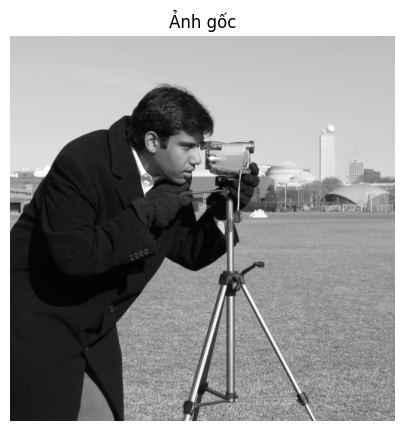

In [1]:
# Nếu thiếu thư viện, bỏ dấu # ở dòng dưới để cài đặt
# %pip install opencv-python scikit-image matplotlib numpy
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, feature, util, exposure

# Ảnh mẫu xám có sẵn trong Scikit-image
img_gray = data.camera().astype(np.uint8)
plt.figure(figsize=(6, 5))#khung hình có chiều rộng,chiều cao
plt.imshow(img_gray, cmap="gray")# Hiển thị ảnh xám
plt.title("Ảnh gốc")
plt.axis("off")# Ẩn các trục tọa độ
plt.show() 

**Nhận xét:** Ảnh mẫu có nhiều vùng sáng tối và chi tiết, phù hợp để quan sát đường biên được phát hiện.

### 2.2. Bài 1: Cài đặt Canny bằng OpenCV và Scikit-image
#### a. OpenCV

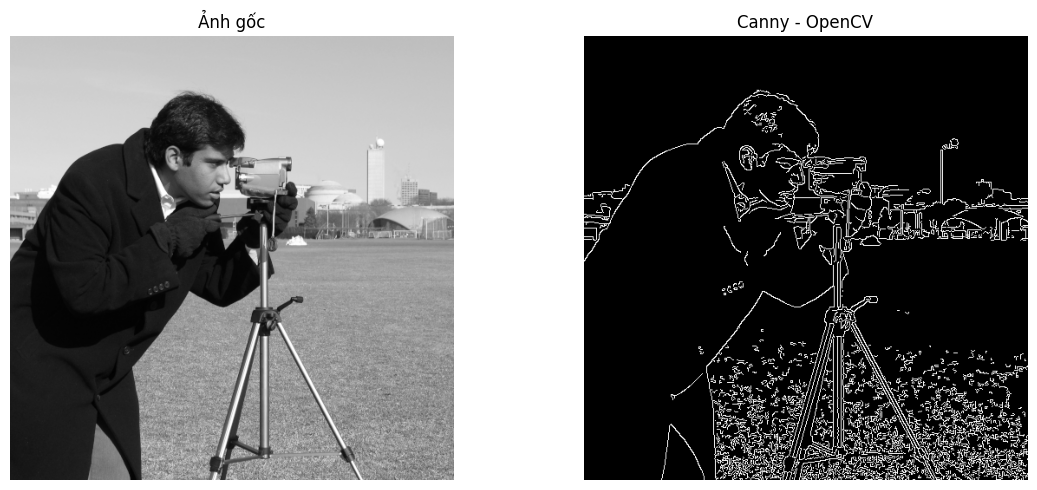

In [2]:
# Canny của OpenCV nhận ngưỡng theo thang cường độ ảnh 0–255
edges_cv = cv2.Canny(img_gray, 100, 200)# Ngưỡng thấp = 100, ngưỡng cao = 200
# Tạo 2 khung hình để so sánh ảnh gốc và ảnh sau xử lý
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(img_gray, cmap="gray")
ax[0].set_title("Ảnh gốc")
ax[1].imshow(edges_cv, cmap="gray")# Hiển thị các cạnh tìm được
ax[1].set_title("Canny - OpenCV")
for a in ax:
    a.axis("off")# Ẩn trục tọa độ
plt.tight_layout()
plt.show()

**Nhận xét:** Các đường màu trắng thể hiện những vùng có thay đổi cường độ sáng rõ.

#### b. Scikit-image

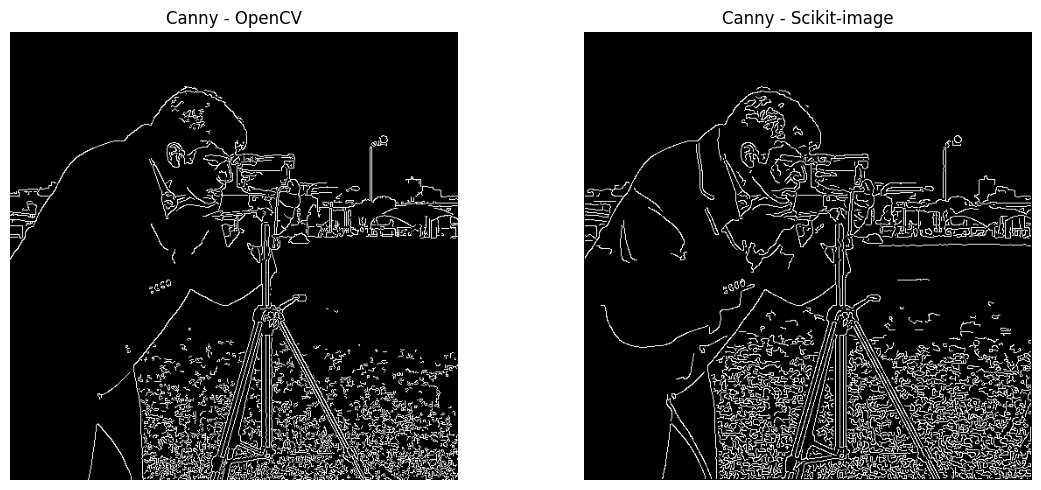

In [3]:
# Scikit-image dùng ngưỡng ảnh chuẩn hóa trong khoảng 0–1
img_float = img_gray.astype(float) / 255.0
edges_sk = feature.canny(
    img_float, sigma=1.0, # Mức độ làm mờ ảnh trước khi tìm cạnh
    low_threshold=0.1, high_threshold=0.2
)

# Tạo 2 khung để so sánh kết quả
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(edges_cv, cmap="gray")
ax[0].set_title("Canny - OpenCV")
ax[1].imshow(edges_sk, cmap="gray")
ax[1].set_title("Canny - Scikit-image")
for a in ax:
    a.axis("off")# Ẩn trục tọa độ
plt.tight_layout()
plt.show()

**Nhận xét:** Cả hai thư viện đều phát hiện được các biên chính. Kết quả có thể khác nhau do cách cài đặt và tham số.

#### c. So sánh với Sobel và Laplacian

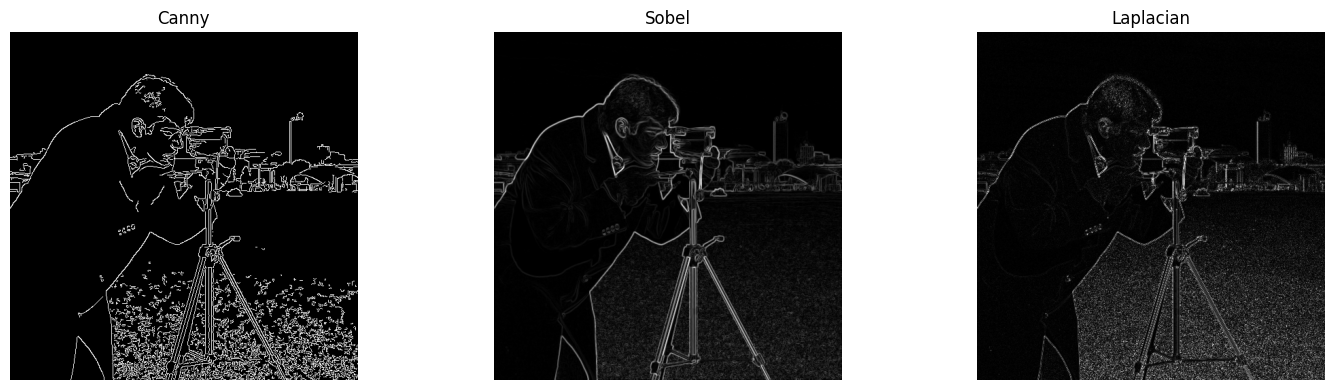

In [4]:
# Sobel: phát hiện cạnh bằng đạo hàm bậc nhất theo 2 hướng
sobel_x = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
# Kết hợp 2 hướng để tính độ mạnh của cạnh
sobel = cv2.magnitude(sobel_x, sobel_y)
# Đưa giá trị ảnh về khoảng 0–255 để hiển thị
sobel = exposure.rescale_intensity(sobel, out_range=(0, 255)).astype(np.uint8)
# Laplacian sử dụng đạo hàm bậc hai phát hiện cạnh
laplacian = cv2.Laplacian(img_gray, cv2.CV_64F)
# Lấy trị tuyệt đối và giới hạn giá trị trong khoảng 0–255
laplacian = np.uint8(np.clip(np.abs(laplacian), 0, 255))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, im, title in zip(
    ax, [edges_cv, sobel, laplacian], ["Canny", "Sobel", "Laplacian"]
):
    a.imshow(im, cmap="gray")
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
plt.show()

**Nhận xét:** Canny thường cho đường biên mảnh hơn. Sobel biểu diễn cường độ gradient, còn Laplacian làm nổi bật những vùng có thay đổi đạo hàm bậc hai.

### 2.3. Bài 2: Thay đổi sigma và ngưỡng
#### a. Thay đổi sigma

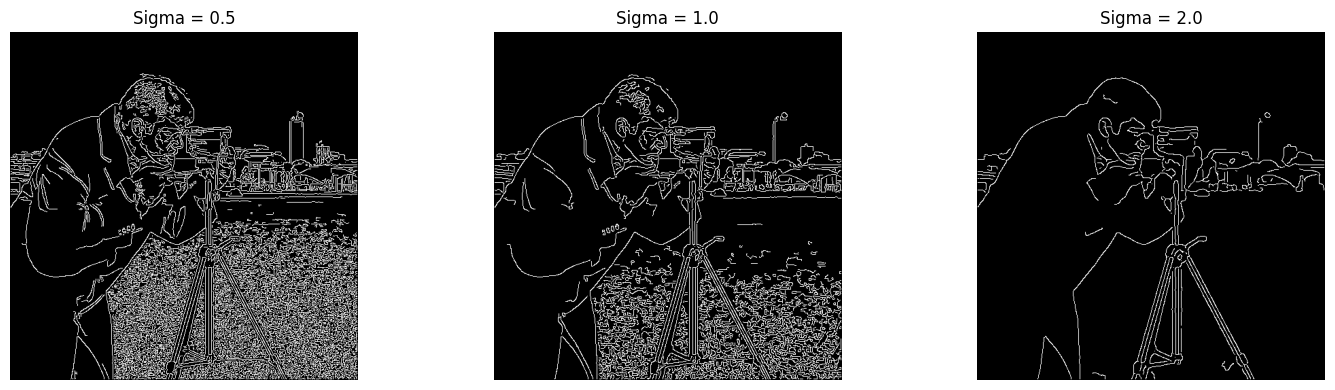

In [5]:
# Thử các mức sigma khác nhau để xem ảnh hưởng đến việc phát hiện cạnh
sigmas = [0.5, 1.0, 2.0]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, sigma in zip(ax, sigmas):
    # Phát hiện cạnh Canny với mức làm mờ sigma khác nhau
    edge = feature.canny(
        img_float, sigma=sigma, low_threshold=0.1, high_threshold=0.2
    )
    a.imshow(edge, cmap="gray")
    a.set_title(f"Sigma = {sigma}")
    a.axis("off")

plt.tight_layout()
plt.show()

**Nhận xét:** Sigma nhỏ thường giữ nhiều chi tiết nhưng dễ có biên do nhiễu. Sigma lớn làm ảnh mượt hơn nhưng có thể bỏ mất biên nhỏ.

#### b. Thay đổi ngưỡng thấp và ngưỡng cao

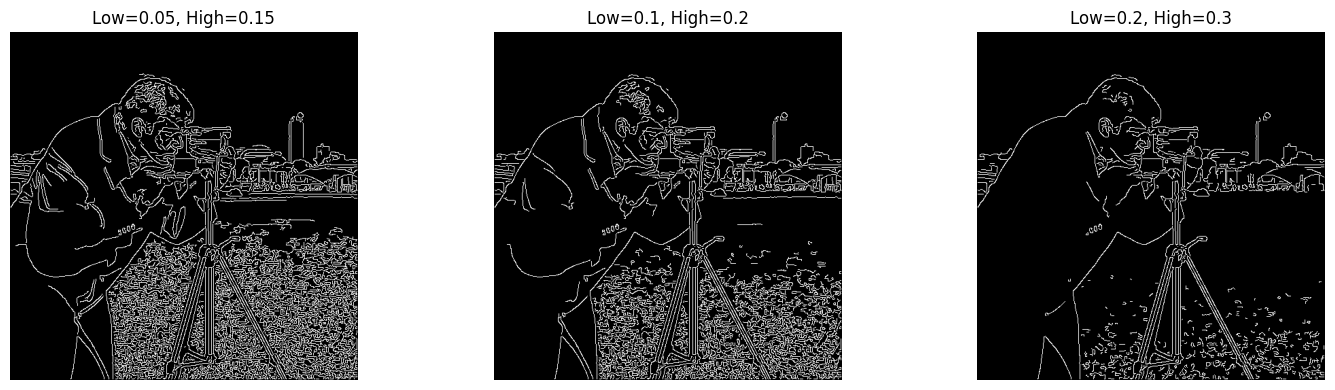

In [6]:
# Thử các cặp ngưỡng thấp và ngưỡng cao khác nhau
thresholds = [(0.05, 0.15), (0.1, 0.2), (0.2, 0.3)]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for a, (low, high) in zip(ax, thresholds):
    # Phát hiện cạnh Canny với cặp ngưỡng tương ứng
    edge = feature.canny(
        img_float, sigma=1.0,
        low_threshold=low, high_threshold=high
    )
    a.imshow(edge, cmap="gray")
    a.set_title(f"Low={low}, High={high}")
    a.axis("off")

plt.tight_layout()
plt.show()

**Nhận xét:** Ngưỡng thấp hơn thường phát hiện nhiều biên hơn, kể cả biên yếu. Ngưỡng cao hơn có thể loại bỏ nhiều biên yếu và giữ lại biên nổi bật.

### 2.4. Bài 3: Ảnh nhiễu, ảnh tương phản thấp và ảnh nhiều chi tiết
#### a. Ảnh có nhiễu

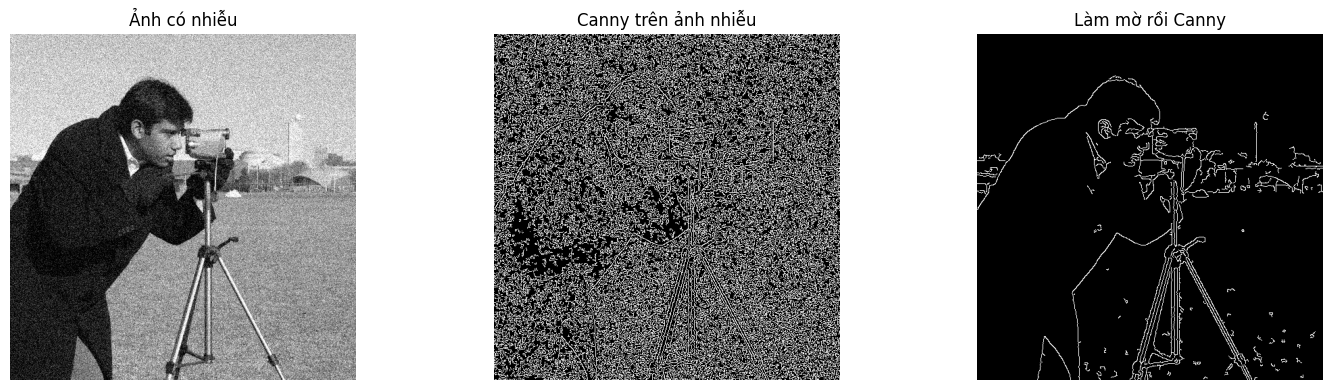

In [7]:
# Thêm nhiễu Gaussian vào ảnh, cố định seed để kết quả không thay đổi mỗi lần chạy
try:
    noisy_float = util.random_noise(
        img_gray, mode="gaussian", var=0.01,
        rng=np.random.default_rng(0)
    )
except TypeError:
    # Dùng seed nếu phiên bản scikit-image không hỗ trợ rng
    noisy_float = util.random_noise(
        img_gray, mode="gaussian", var=0.01, seed=0
    )
# Chuyển ảnh nhiễu về khoảng 0–255
noisy_img = (noisy_float * 255).astype(np.uint8)
# Phát hiện cạnh trực tiếp trên ảnh nhiễu
edges_noisy = cv2.Canny(noisy_img, 100, 200)
# Làm mờ ảnh để giảm nhiễu trước khi phát hiện cạnh
blurred = cv2.GaussianBlur(noisy_img, (5, 5), 1.0)
# Phát hiện cạnh sau khi giảm nhiễu
edges_denoised = cv2.Canny(blurred, 100, 200)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, im, title in zip(
    ax,
    [noisy_img, edges_noisy, edges_denoised],
    ["Ảnh có nhiễu", "Canny trên ảnh nhiễu", "Làm mờ rồi Canny"]
):
    a.imshow(im, cmap="gray")
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
plt.show()

**Nhận xét:** Nhiễu có thể tạo biên giả. Làm mờ Gaussian trước khi chạy Canny giúp giảm một phần nhiễu, nhưng làm mờ quá mạnh có thể làm mất chi tiết.

#### b. Ảnh có độ tương phản thấp

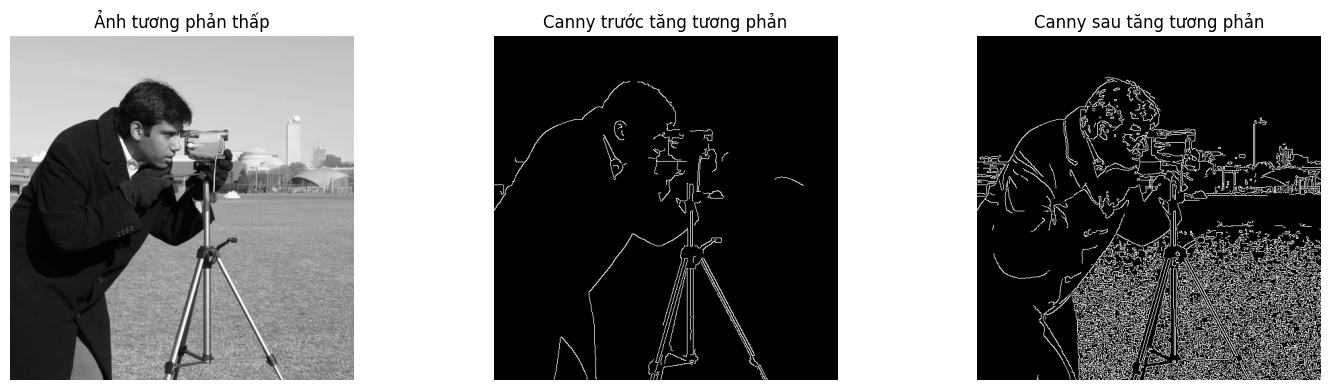

In [8]:
# Giảm độ tương phản của ảnh
low_contrast = cv2.convertScaleAbs(img_gray, alpha=0.35, beta=80)
edges_low = cv2.Canny(low_contrast, 100, 200)# Phát hiện cạnh trước khi tăng tương phản

# Cân bằng histogram để cải thiện độ tương phản
enhanced = cv2.equalizeHist(low_contrast)
edges_enhanced = cv2.Canny(enhanced, 100, 200) # Phát hiện cạnh sau khi tăng tương phản

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, im, title in zip(
    ax,
    [low_contrast, edges_low, edges_enhanced],
    ["Ảnh tương phản thấp", "Canny trước tăng tương phản", "Canny sau tăng tương phản"]
):
    a.imshow(im, cmap="gray")
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
plt.show()

**Nhận xét:** Cân bằng histogram có thể làm nổi bật sự khác biệt cường độ sáng và giúp phát hiện thêm một số biên.

#### c. Ảnh nhiều chi tiết

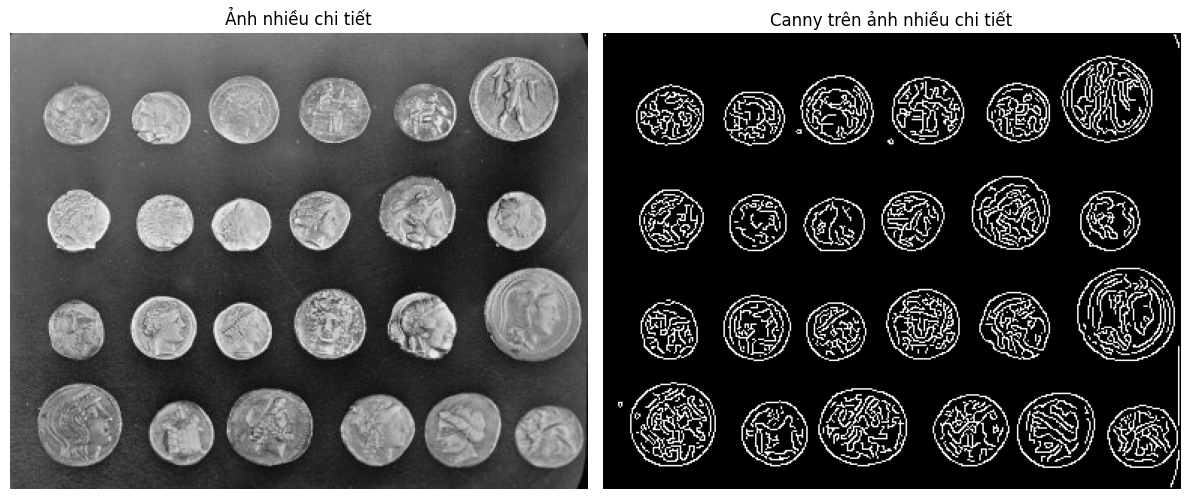

In [9]:
# Lấy ảnh mẫu đồng xu có nhiều chi tiết
detail_img = data.coins()
# Chuẩn hóa ảnh về khoảng 0–1
detail_float = detail_img.astype(float) / 255.0
# Phát hiện cạnh bằng thuật toán Canny
edges_detail = feature.canny(
    detail_float, sigma=1.0, low_threshold=0.1, high_threshold=0.2
)
# Hiển thị ảnh gốc và ảnh phát hiện cạnh
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(detail_img, cmap="gray")
ax[0].set_title("Ảnh nhiều chi tiết")
ax[1].imshow(edges_detail, cmap="gray")
ax[1].set_title("Canny trên ảnh nhiều chi tiết")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

**Nhận xét:** Canny phát hiện đường viền của đồng xu và nhiều chi tiết khác. Các vùng tiếp xúc hoặc chi tiết nhỏ có thể tạo ra đường biên phức tạp.

### 2.5. Bài 4: Kết hợp Canny với phân đoạn và nhận dạng hình dạng

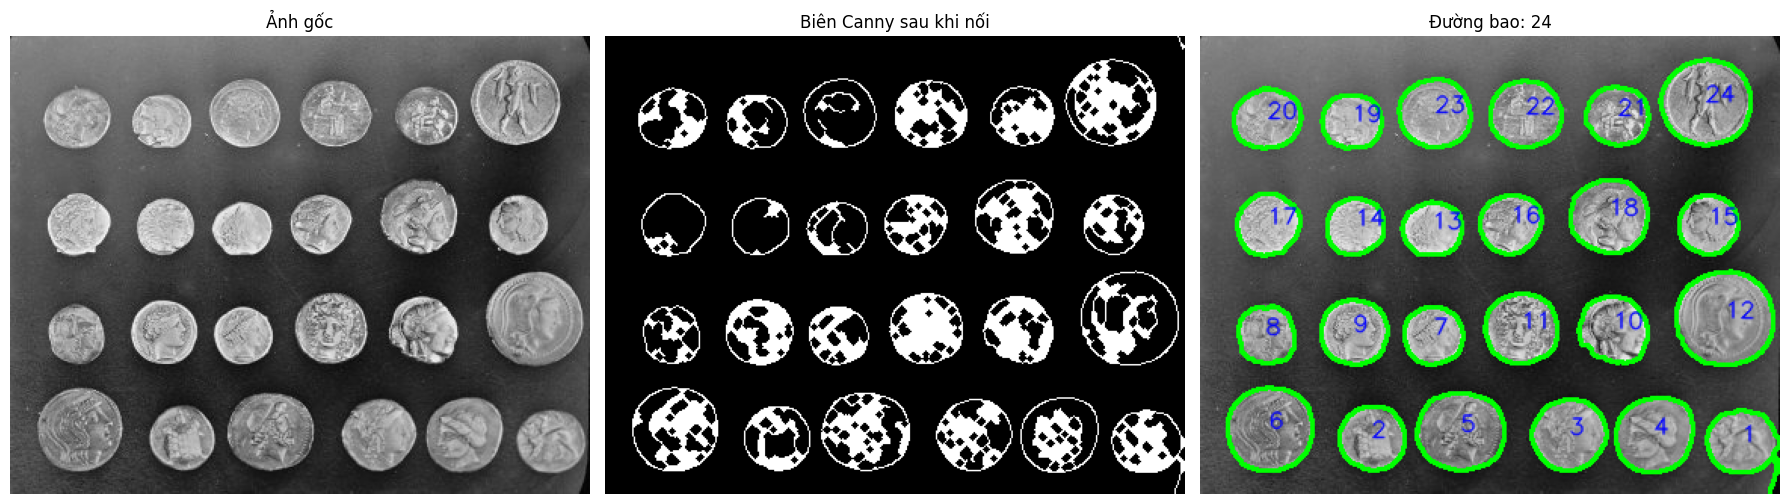

Số đường bao tìm được: 24


In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, img_as_ubyte

# Đọc ảnh đồng xu
coins = img_as_ubyte(data.coins())
# làm mờ ảnh để Giảm nhiễu
blurred = cv2.GaussianBlur(coins, (5, 5), 1.2)
# Phát hiện biên bằng canny
edges = cv2.Canny(blurred, 30, 100)
# Nối các đoạn biên bị đứt
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
edges_closed = cv2.morphologyEx(
    edges, cv2.MORPH_CLOSE, kernel, iterations=2
)

# Tìm đường bao bên ngoài
contours, _ = cv2.findContours(
    edges_closed.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Lọc đường bao nhỏ
min_area = 150
valid_contours = [
    c for c in contours
    if cv2.contourArea(c) > min_area
]
# Chuyển ảnh xám sang ảnh màu để vẽ đường bao
result = cv2.cvtColor(coins, cv2.COLOR_GRAY2BGR)
# Vẽ đường bao và đánh số từng vật thể
for i, contour in enumerate(valid_contours, start=1):
    cv2.drawContours(result, [contour], -1, (0, 255, 0), 2)
    # Tính tâm của đường bao
    M = cv2.moments(contour)
    if M["m00"] != 0:
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])
        # Ghi số thứ tự tại tâm vật thể
        cv2.putText(
            result, str(i), (cx, cy),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5,
            (255, 0, 0), 1, cv2.LINE_AA
        )

# Hiển thị
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

ax[0].imshow(coins, cmap="gray")
ax[0].set_title("Ảnh gốc")
ax[1].imshow(edges_closed, cmap="gray")
ax[1].set_title("Biên Canny sau khi nối")
ax[2].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
ax[2].set_title(f"Đường bao: {len(valid_contours)}")

for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()
# In số lượng đường bao được giữ lại sau khi lọc
print("Số đường bao tìm được:", len(valid_contours))

**Nhận xét:** Canny làm nổi bật ranh giới, còn `findContours` tìm đường bao để hỗ trợ nhận dạng hình dạng. Kết quả phụ thuộc vào chất lượng biên và cách xử lý ảnh.

# 3. CÂU HỎI MỞ RỘNG

## Câu 1. Làm thế nào để đánh giá chất lượng biên?
Có thể đánh giá dựa trên độ chính xác so với đường viền thực tế, tính liên tục, độ mảnh, khả năng chống nhiễu và khả năng giữ chi tiết. Nếu có ảnh chuẩn, có thể sử dụng Precision, Recall và F1-score.

## Câu 2. Có thể cải thiện Canny như thế nào?
Có thể giảm nhiễu trước khi xử lý, điều chỉnh sigma và hai ngưỡng, tăng tương phản cho ảnh kém chất lượng, hoặc kết hợp với phân đoạn ảnh và các phép toán hình thái. Cách phù hợp phụ thuộc vào ảnh đầu vào.

## Câu 3. Có thể áp dụng Canny cho ảnh màu không?
Có. Cách đơn giản là chuyển ảnh màu sang ảnh xám rồi áp dụng Canny. Cách này dễ thực hiện nhưng có thể bỏ qua biên chỉ thể hiện rõ qua khác biệt màu sắc.

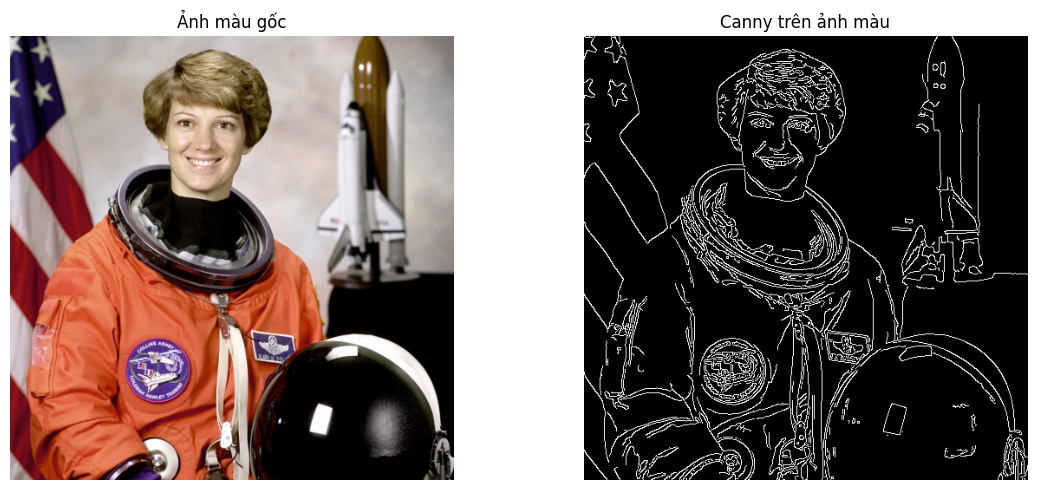

In [11]:
# Ví dụ: áp dụng Canny cho ảnh màu sau khi chuyển sang ảnh xám
color_img = data.astronaut()
gray_color = cv2.cvtColor(color_img, cv2.COLOR_RGB2GRAY)
color_edges = cv2.Canny(gray_color, 100, 200)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(color_img)
ax[0].set_title("Ảnh màu gốc")
ax[1].imshow(color_edges, cmap="gray")
ax[1].set_title("Canny trên ảnh màu")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

## Câu 4. Có thể áp dụng Canny cho video không?
Có. Có thể đọc từng khung hình, chuyển sang ảnh xám rồi chạy Canny. Ví dụ dưới đây sử dụng webcam trên máy tính; nhấn `q` để thoát. Trên Google Colab, webcam thường không truy cập trực tiếp bằng đoạn code này nên cần chạy trên máy tính hoặc dùng tệp video.

In [12]:
# Ví dụ webcam (chỉ chạy trên máy có webcam; nhấn q để thoát).
# Không tự chạy khi bấm Run All để tránh lỗi nếu môi trường không có webcam.
# Bỏ dấu # ở các dòng dưới nếu muốn chạy riêng trên máy tính.
# cap = cv2.VideoCapture(0)
# while cap.isOpened():
#     ret, frame = cap.read()
#     if not ret:
#         break
#     gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
#     edges = cv2.Canny(gray, 100, 200)
#     cv2.imshow("Video Canny", edges)
#     if cv2.waitKey(1) & 0xFF == ord("q"):
#         break
# cap.release()
# cv2.destroyAllWindows()

## Kết luận
Canny là phương pháp phát hiện biên hiệu quả, giúp làm nổi bật đường viền của đối tượng. Kết quả phụ thuộc vào độ nhiễu, độ tương phản và tham số được lựa chọn. Khi kết hợp với tìm đường bao và phân đoạn ảnh, Canny có thể hỗ trợ nhận dạng hình dạng và nhiều bài toán thị giác máy tính.